# 01 — TON_IoT Data Audit and EDA

## Purpose

This notebook documents the dataset before modeling. It provides the evidence for the report sections **Dataset Description and Data Dictionary**, **Data Quality Assessment**, and **Exploratory Data Analysis**.

The project question is whether network-flow data can be used to distinguish normal IoT/IIoT traffic from attacks and identify attack categories. MITM is treated as an important rare class.


## Report insight

At the end of this notebook, we should be able to describe the dataset, its labels, its quality issues, the class imbalance, and the possible leakage risk. We should not claim that the data are perfect; we should explain what was checked and what remains a limitation.


In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Works whether you run from the repo root or from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
DATA_PATH = DATA_DIR / "train_test_network.csv"
if not DATA_PATH.exists():
    alternatives = list(DATA_DIR.glob("*.csv"))
    if alternatives:
        DATA_PATH = alternatives[0]
    else:
        raise FileNotFoundError(f"No CSV found in {DATA_DIR}. Update DATA_PATH with the exact filename.")

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (FIGURES_DIR, METRICS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_PATH)


Dataset: data\train_test_network.csv


## 1. Load the dataset and check its size

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())


Dataset loaded successfully
Rows: 211043
Columns: 44


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


**Report interpretation:** The working TON_IoT network-flow file contains the rows and variables shown above. Each row represents one labeled network-flow observation.

## 2. Review columns, data types, and missing values

In [3]:
data_profile = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "unique_values": [df[column].nunique(dropna=False) for column in df.columns],
    "missing_values": [df[column].isna().sum() for column in df.columns],
    "dash_placeholders": [(df[column].astype(str).str.strip() == "-").sum() for column in df.columns],
})
display(data_profile)
data_profile.to_csv(METRICS_DIR / "data_profile.csv", index=False)
print("Total missing cells:", int(df.isna().sum().sum()))
print("Total '-' placeholders:", int((df.astype(str) == "-").sum().sum()))


,column,dtype,unique_values,missing_values,dash_placeholders
0,src_ip,object,51,0,0
1,src_port,int64,26628,0,0
2,dst_ip,object,753,0,0
3,dst_port,int64,2039,0,0
4,proto,object,3,0,0
5,service,object,9,0,132032
6,duration,float64,68570,0,0
7,src_bytes,int64,2199,0,0
8,dst_bytes,int64,2338,0,0
9,conn_state,object,13,0,0


Total missing cells: 0
Total '-' placeholders: 4384861


**Report interpretation:** A dash is common in network logs when a field is not applicable or was not observed. These values will be handled during preprocessing instead of being treated automatically as attacks.

## 3. Check duplicate and invalid records

In [4]:
print("Duplicate rows:", int(df.duplicated().sum()))

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
validity = []
for column in numeric_columns:
    values = pd.to_numeric(df[column], errors="coerce")
    validity.append({
        "column": column,
        "negative_values": int((values < 0).sum()),
        "zero_values": int((values == 0).sum()),
        "minimum": values.min(),
        "maximum": values.max(),
    })
validity = pd.DataFrame(validity)
display(validity)
validity.to_csv(METRICS_DIR / "numeric_validity.csv", index=False)


Duplicate rows: 20569


,column,negative_values,zero_values,minimum,maximum
0,src_port,0,0,1.0,6.552800e+04
1,dst_port,0,34,0.0,6.546700e+04
2,duration,0,60013,0.0,9.351693e+04
3,src_bytes,0,138156,0.0,3.890855e+09
4,dst_bytes,0,148893,0.0,3.913853e+09
5,missed_bytes,0,208098,0.0,1.854527e+09
6,src_pkts,0,17094,0.0,2.462300e+04
7,src_ip_bytes,0,17094,0.0,6.522626e+06
8,dst_pkts,0,83234,0.0,1.219420e+05
9,dst_ip_bytes,0,83234,0.0,8.639552e+07


**Report interpretation:** Duplicate records are reported before any removal. Extreme values are recorded as potential outliers. Network byte and packet counts can legitimately be highly skewed, so they should not be deleted without checking their meaning.

## 4. Inspect the prediction targets

In [5]:
print("Binary target distribution")
display(df["label"].value_counts(dropna=False).sort_index().rename("records").to_frame())
print("Attack-category distribution")
display(df["type"].value_counts(dropna=False).rename("records").to_frame())

df["label"].value_counts().rename("records").to_csv(METRICS_DIR / "binary_class_counts.csv")
df["type"].value_counts().rename("records").to_csv(METRICS_DIR / "attack_category_counts.csv")


Binary target distribution


,records
label,
0,50000
1,161043


Attack-category distribution


,records
type,
normal,50000
backdoor,20000
ddos,20000
dos,20000
injection,20000
password,20000
ransomware,20000
scanning,20000
xss,20000


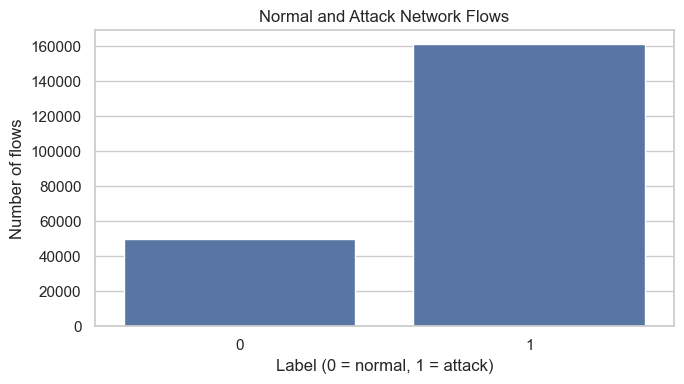

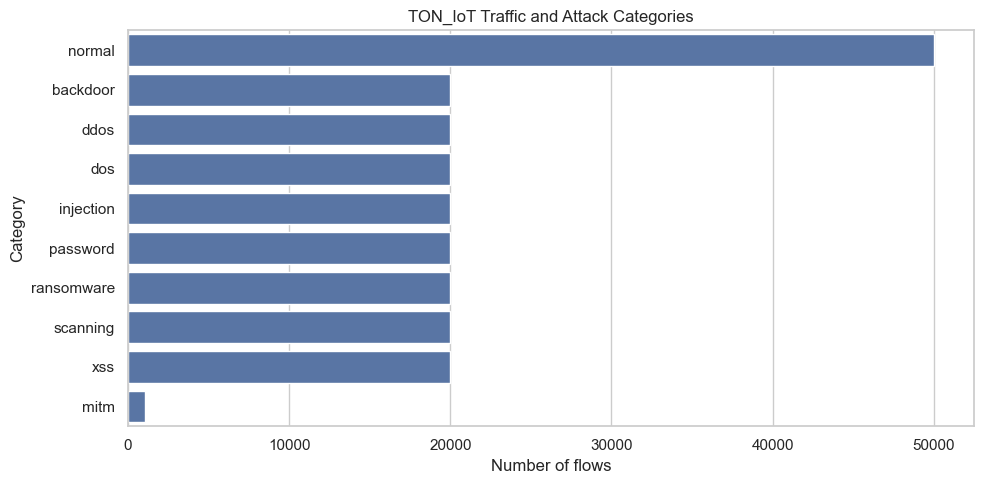

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label", order=sorted(df["label"].dropna().unique()))
plt.title("Normal and Attack Network Flows")
plt.xlabel("Label (0 = normal, 1 = attack)")
plt.ylabel("Number of flows")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "normal_vs_attack.png", dpi=200)
plt.show()

plt.figure(figsize=(10, 5))
order = df["type"].value_counts().index
sns.countplot(data=df, y="type", order=order)
plt.title("TON_IoT Traffic and Attack Categories")
plt.xlabel("Number of flows")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "attack_categories.png", dpi=200)
plt.show()


**Report insight:** The attack classes are not equally represented. MITM has far fewer records than the other categories, so later evaluation should include MITM recall and macro-F1 instead of relying only on accuracy.

## 5. Identify categorical, numerical, and identifier fields

In [7]:
identifier_columns = [c for c in ["src_ip", "dst_ip", "uid", "id", "flow_id", "timestamp"] if c in df.columns]
feature_df = df.drop(columns=["label", "type"], errors="ignore")
categorical_columns = feature_df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numerical_columns = feature_df.select_dtypes(include=np.number).columns.tolist()

print("Identifier columns:", identifier_columns)
print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

column_roles = pd.DataFrame({
    "column": feature_df.columns,
    "role": ["identifier" if c in identifier_columns else "categorical" if c in categorical_columns else "numerical" if c in numerical_columns else "other" for c in feature_df.columns]
})
display(column_roles)
column_roles.to_csv(METRICS_DIR / "column_roles.csv", index=False)


Identifier columns: ['src_ip', 'dst_ip']
Categorical columns: ['src_ip', 'dst_ip', 'proto', 'service', 'conn_state', 'dns_query', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']
Numerical columns: ['src_port', 'dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_request_body_len', 'http_response_body_len', 'http_status_code']


,column,role
0,src_ip,identifier
1,src_port,numerical
2,dst_ip,identifier
3,dst_port,numerical
4,proto,categorical
5,service,categorical
6,duration,numerical
7,src_bytes,numerical
8,dst_bytes,numerical
9,conn_state,categorical


## 6. Check possible IP-address leakage

In [8]:
for column in identifier_columns:
    print(f"Leakage check for {column}")
    leakage = df.groupby(column, dropna=False).agg(
        records=("label", "size"),
        attack_rate=("label", "mean"),
        unique_labels=("label", "nunique"),
    ).sort_values("records", ascending=False)
    print("Unique values:", df[column].nunique(dropna=False))
    display(leakage.head(10))


Leakage check for src_ip
Unique values: 51


,records,attack_rate,unique_labels
src_ip,,,
192.168.1.30,61633,0.999221,2
192.168.1.31,30355,1.000000,1
192.168.1.32,27227,1.000000,1
192.168.1.193,25000,0.921880,2
192.168.1.152,21893,0.000091,2
192.168.1.33,9439,1.000000,1
192.168.1.37,7500,1.000000,1
192.168.1.195,4208,0.000475,2
192.168.1.180,3708,0.000000,1


Leakage check for dst_ip
Unique values: 753


,records,attack_rate,unique_labels
dst_ip,,,
192.168.1.190,47795,0.526206,2
192.168.1.193,23790,0.930517,2
192.168.1.152,22701,0.621823,2
192.168.1.195,13524,0.852484,2
192.168.1.184,12528,0.869013,2
192.168.1.33,12041,1.000000,1
192.168.1.37,11020,1.000000,1
192.168.1.1,10623,0.957357,2
176.28.50.165,9315,1.000000,1


**Report interpretation:** IP addresses and identifiers can allow a model to memorize the environment instead of learning general attack behavior. They are excluded from the main model. A future capture/device/time-disjoint split is still needed to test generalization more strictly.

## 7. Basic numerical distributions and outliers

,column,outlier_count,q1,q3
2,duration,47670,0.0,0.054196
9,dst_ip_bytes,43437,0.0,134.000000
4,dst_bytes,43158,0.0,89.000000
1,dst_port,40690,65.0,1253.000000
0,src_port,39337,34608.0,51133.000000
10,dns_qclass,34768,0.0,0.000000
11,dns_qtype,34768,0.0,0.000000
8,dst_pkts,24273,0.0,2.000000
7,src_ip_bytes,21624,48.0,415.000000
6,src_pkts,15412,1.0,4.000000


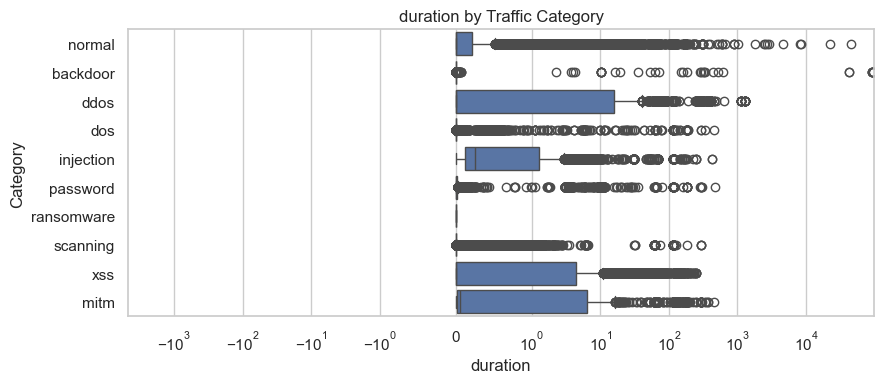

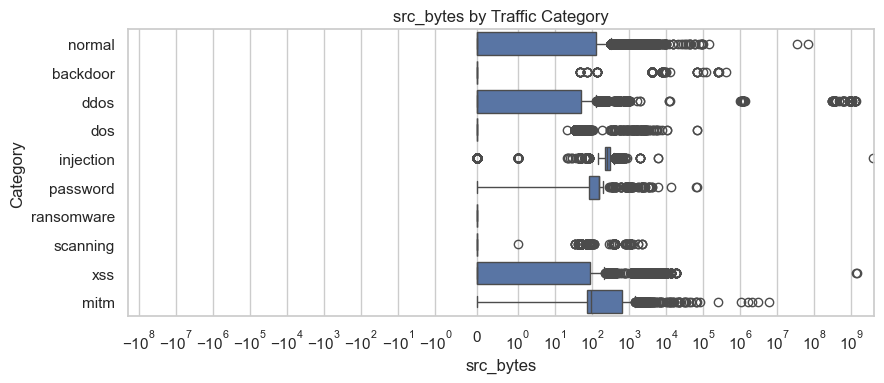

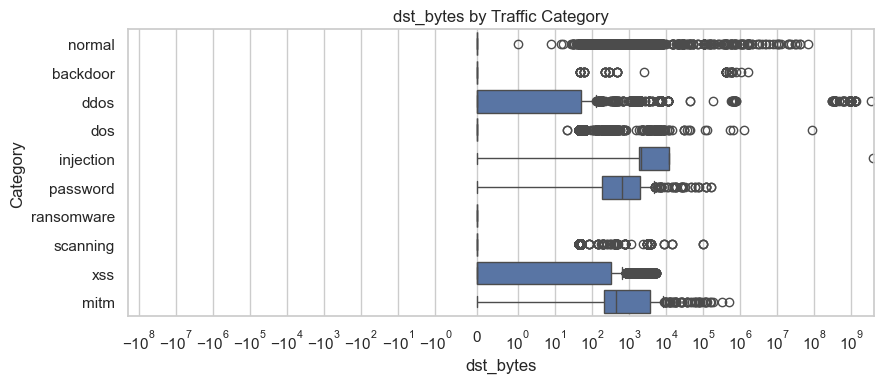

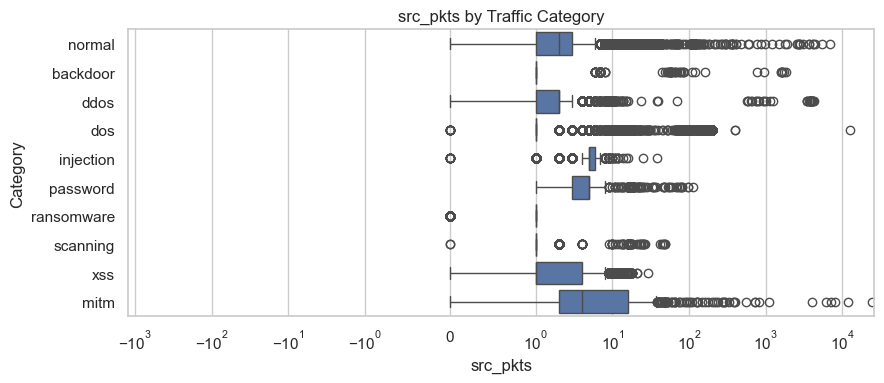

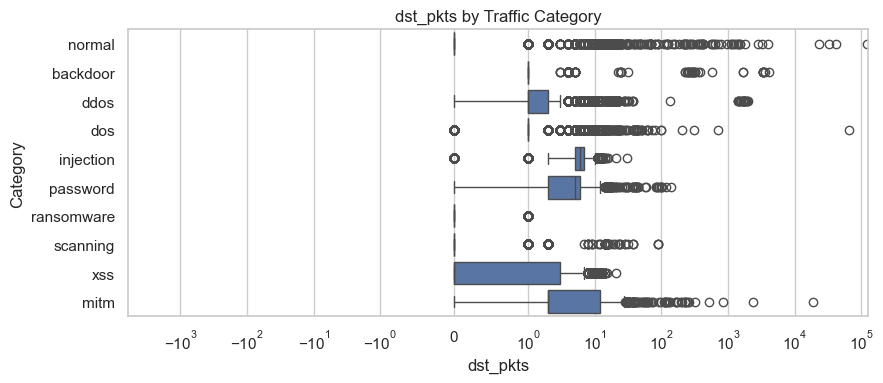

In [9]:
outlier_rows = []
for column in numerical_columns:
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"column": column, "outlier_count": int(((values < lower) | (values > upper)).sum()), "q1": q1, "q3": q3})
outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_count", ascending=False)
display(outlier_summary)
outlier_summary.to_csv(METRICS_DIR / "outlier_summary.csv", index=False)

selected = [c for c in ["duration", "src_bytes", "dst_bytes", "src_pkts", "dst_pkts"] if c in numerical_columns]
for column in selected:
    plt.figure(figsize=(9, 4))
    sns.boxplot(data=df, x=column, y="type", order=df["type"].value_counts().index)
    plt.xscale("symlog", linthresh=1)
    plt.title(f"{column} by Traffic Category")
    plt.xlabel(column)
    plt.ylabel("Category")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{column}_by_category.png", dpi=180)
    plt.show()


**Report interpretation:** These plots help identify whether traffic categories differ in duration, bytes, or packet counts. Outliers are recorded but not automatically deleted because unusually large flows may be meaningful attack behavior.

## 8. EDA conclusions for the report

Use the actual outputs from this notebook to complete these points:

- The dataset contains labeled normal and attack network flows.
- The binary target is `label`; the multiclass target is `type`.
- Attack classes are imbalanced, with MITM as the rare class.
- IP-address fields may create environment leakage and are excluded from the main model.
- Placeholder values and skewed numerical features require preprocessing.
- The initial random split is useful for a baseline, but a stricter capture/device/time split should be future work.
